# Part 2 — Borrower Profiles (K-Means)
**Beyond Credit Scores: Discovering Borrower Risk Profiles and Early Warning Patterns for Loan Default**
DSAI 4102 Applied Data Mining · Group 1 · Kelvin Sergio (60106790)

**Goal:** split borrowers into a small number of profiles that look alike financially, then check whether those
profiles default at different rates.

**Key point:** the clustering never sees grade, interest rate or FICO. The profiles are built from the borrowers'
finances alone, so if they default differently, that's a pattern found without Lending Club's own score.

| Step | What it does |
|---|---|
| 1 | Load Part 1's clean data and scale the features |
| 2 | Compare K = 2 to 10 and choose K |
| 3 | Fit the final model and describe each profile |
| 4 | Default rate per profile + significance test |
| 5 | Check the profiles against grade and save the results |

**Outputs:** `data/processed/clusters_kmeans.csv` (each loan's profile, used by Parts 3 and 4),
`data/processed/profile_summary.csv`, `figures/02_*.png`

### Step 1 · Load and scale

In [14]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

# Settings
K_VALUES = range(2, 11)  # candidate numbers of profiles
N_INIT = 10  # Note: K-Means depends on its random start, so it runs 10 times and keeps the best
SIL_SAMPLE = 30_000  # Note: silhouette compares every pair of points; a fixed 30k sample keeps it fast and repeatable
FINAL_K = 6  # Note: chosen in Step 2

plt.rcParams.update(
    {"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False}
)
BLUE, ORANGE = "#2a78d6", "#eb6834"

# The column lists come from Part 1, so every part of the project uses the same features.
fs = json.loads((DATA_DIR / "feature_sets.json").read_text())
SEED = fs["random_state"]
FEATURES = fs["cluster_numeric"]

df = pd.read_parquet(DATA_DIR / fs["data_file"])
base_rate = df["default"].mean()
print(
    f"{len(df):,} loans | {len(FEATURES)} features | overall default rate {base_rate:.1%}"
)

673,314 loans | 14 features | overall default rate 14.8%


In [15]:
# Why scale: K-Means groups points by distance. Utilisation runs 0-100 while public record is 0/1, so without
# scaling the big-number features would decide everything. After scaling, every feature has mean 0 and
# standard deviation 1, so each one counts equally.
X = StandardScaler().fit_transform(df[FEATURES])

### Step 2 · Choose the number of profiles (K)

In [16]:
# Three checks for each K:
#   inertia     - total distance from borrowers to their profile centre (lower = tighter). It always drops
#                 as K grows, so we look for where it stops dropping fast (the "elbow").
#   silhouette  - how clearly each borrower belongs to its own profile rather than the next one (-1 to 1).
#   risk spread - default rate of the riskiest profile / the safest. This answers our actual question:
#                 do the profiles separate risk?
rng = np.random.default_rng(SEED)
sample = rng.choice(len(X), SIL_SAMPLE, replace=False)

rows = []
for k in K_VALUES:
    km = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(X)
    rates = df["default"].groupby(km.labels_).mean()
    rows.append(
        {
            "K": k,
            "inertia": km.inertia_,
            "silhouette": silhouette_score(X[sample], km.labels_[sample]),
            "risk_spread": rates.max() / rates.min(),
            "smallest_profile_%": np.bincount(km.labels_).min() / len(X) * 100,
        }
    )
k_table = pd.DataFrame(rows).set_index("K")
k_table.round(3)

,inertia,silhouette,risk_spread,smallest_profile_%
K,,,,
2,8245789.005,0.130,1.069,42.996
3,7694639.265,0.134,1.228,14.885
4,7222963.435,0.118,1.468,14.013
5,6873681.605,0.092,1.711,9.348
6,6537800.118,0.092,1.874,5.539
7,6337606.829,0.084,1.861,5.383
8,6153658.039,0.081,1.969,5.154
9,6000489.635,0.082,2.184,4.959
10,5864975.499,0.080,2.167,4.843


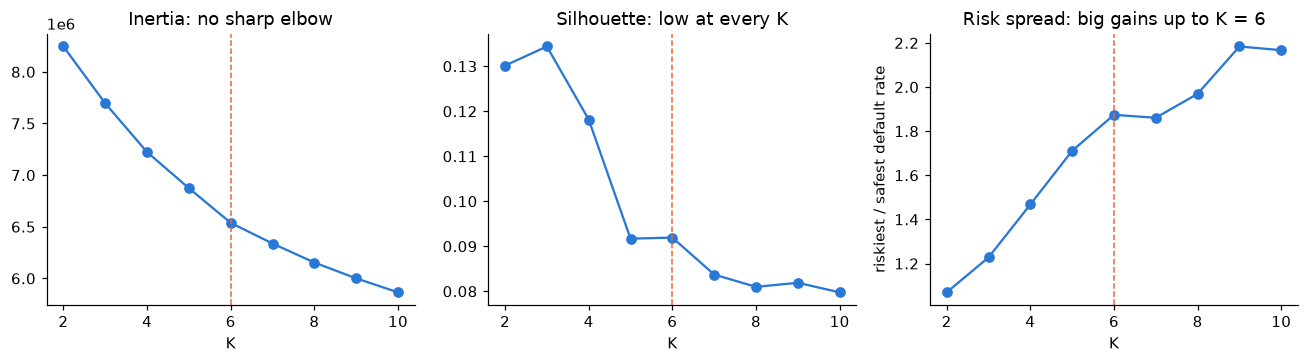

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, col, title in zip(
    axes,
    ["inertia", "silhouette", "risk_spread"],
    [
        "Inertia: no sharp elbow",
        "Silhouette: low at every K",
        "Risk spread: big gains up to K = 6",
    ],
):
    ax.plot(k_table.index, k_table[col], marker="o", color=BLUE)
    ax.axvline(FINAL_K, color=ORANGE, linestyle="--", linewidth=1)
    ax.set(title=title, xlabel="K")
axes[2].set_ylabel("riskiest / safest default rate")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_k_selection.png", dpi=200, bbox_inches="tight")
plt.show()

**Decision: K = 6.**
- **Inertia** falls steadily with no clear elbow, so it can't pick K on its own.
- **Silhouette** is low everywhere (0.08–0.13). Borrowers form a continuum rather than separate groups, which is normal
  for financial data. It holds at 0.092 from K = 5 to 6, so moving to 6 costs nothing in separation.
- **Risk spread** climbs from 1.71× at K = 5 to 1.87× at K = 6, then stalls at K = 7 (1.86×). K = 8–9 push it up to
  2.18×, but only by adding more small profiles (about 5% of loans each) while silhouette drops further. Nine profiles
  is too many for a lender to work with.
- Six profiles separate risk well and are still easy to describe and act on.

### Step 3 · Fit the final model and describe the profiles

In [18]:
km = KMeans(n_clusters=FINAL_K, n_init=N_INIT, random_state=SEED).fit(X)

# Note: K-Means numbers clusters in no particular order. We renumber them by default rate,
# so profile 1 is always the safest and profile 6 the riskiest.
order = df["default"].groupby(km.labels_).mean().sort_values().index
new_number = {old: new for new, old in enumerate(order, start=1)}
df["profile"] = pd.Series(km.labels_).map(new_number).values

# Profile centres in scaled units: +1 means one standard deviation above the average borrower.
centres = (
    pd.DataFrame(km.cluster_centers_, columns=FEATURES)
    .rename(index=new_number)
    .sort_index()
)

# Each profile is named after the feature where it stands out most (largest centre value, + or -).
NAMES = {
    "mort_acc": "Established homeowners",
    "total_acc": "Thin-file starters",
    "delinq_2yrs": "Recent delinquents",
    "has_public_record": "Public-record borrowers",
    "open_acc": "Heavy credit users",
    "loan_to_income": "Stretched borrowers",
}
standout = centres.abs().idxmax(axis=1)
names = {p: NAMES.get(feature, f"Profile {p}") for p, feature in standout.items()}
df["profile_name"] = df["profile"].map(names)
pd.DataFrame({"stands out on": standout, "name": pd.Series(names)})

,stands out on,name
1,mort_acc,Established homeowners
2,total_acc,Thin-file starters
3,delinq_2yrs,Recent delinquents
4,has_public_record,Public-record borrowers
5,open_acc,Heavy credit users
6,loan_to_income,Stretched borrowers


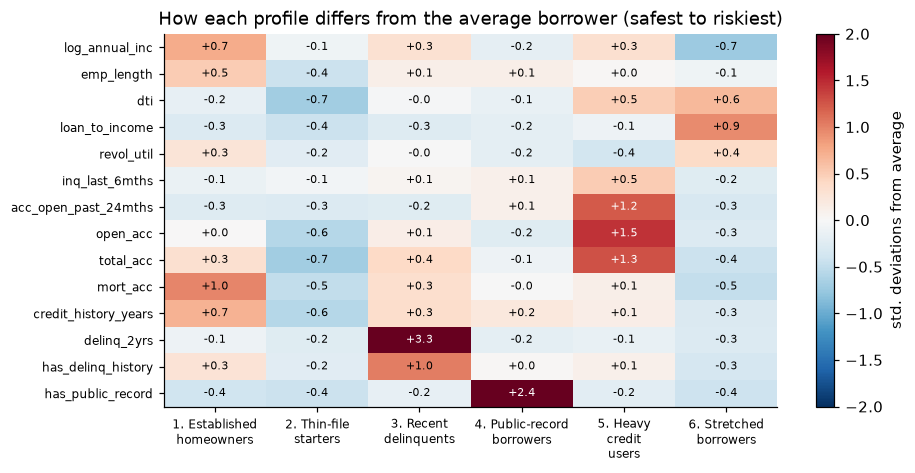

In [19]:
fig, ax = plt.subplots(figsize=(9, 4.4))
im = ax.imshow(centres.T, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(
    range(FINAL_K),
    [f"{p}. " + names[p].replace(" ", "\n") for p in centres.index],
    fontsize=8,
)
ax.set_yticks(range(len(FEATURES)), FEATURES, fontsize=8)
for (i, j), value in np.ndenumerate(centres.T.values):
    ax.text(
        j,
        i,
        f"{value:+.1f}",
        ha="center",
        va="center",
        fontsize=7,
        color="white" if abs(value) > 1.2 else "black",
    )
fig.colorbar(im, ax=ax, label="std. deviations from average")
ax.set_title("How each profile differs from the average borrower (safest to riskiest)")
fig.savefig(FIG_DIR / "02_profile_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

In [20]:
# Same profiles in everyday units - this is how we'd explain them to a lender.
cols = [
    "annual_inc",
    "dti",
    "loan_to_income",
    "revol_util",
    "open_acc",
    "acc_open_past_24mths",
    "mort_acc",
    "credit_history_years",
    "delinq_2yrs",
    "has_public_record",
]
everyday = df.groupby("profile")[cols].mean()
everyday.loc["All"] = df[cols].mean()
everyday.T.round(2)
# Result, safest to riskiest:
#   1 Established homeowners  - top income (~$103k), most mortgages, longest credit history.
#   2 Thin-file starters      - shortest history (~12 yrs) and fewest accounts, but the LOWEST debt (DTI ~12).
#                               A short history on its own isn't risky when debt is low.
#   3 Recent delinquents      - every borrower here missed a payment in the last 2 years.
#   4 Public-record borrowers - every borrower here has a public record (e.g. a bankruptcy).
#   5 Heavy credit users      - ~19 open accounts, ~8 of them opened in the last 2 years.
#   6 Stretched borrowers     - lowest income (~$46k), biggest loans for their income (0.30), highest DTI and
#                               utilisation.

profile,1,2,3,4,5,6,All
annual_inc,103248.57,66506.23,83025.91,64036.13,82147.41,45951.49,72011.40
dti,16.19,11.91,17.30,16.34,21.57,22.79,17.54
loan_to_income,0.17,0.16,0.17,0.18,0.19,0.30,0.20
revol_util,60.14,48.87,54.13,49.51,45.38,63.47,54.19
open_acc,11.27,8.36,11.87,9.97,18.61,9.87,11.23
acc_open_past_24mths,3.58,3.55,3.61,4.60,7.69,3.42,4.30
mort_acc,3.50,0.65,2.28,1.59,1.83,0.70,1.61
credit_history_years,21.22,11.79,18.63,17.66,17.03,13.96,16.07
delinq_2yrs,0.22,0.11,2.83,0.16,0.19,0.10,0.30
has_public_record,0.01,0.00,0.09,1.00,0.08,0.01,0.15


**Note on profiles 3 and 4.** Each is built around one past problem: recent missed payments (profile 3) and a
public record (profile 4). Rare traits stand far from average once scaled: 15% of borrowers have a public record,
so a "yes" sits about 2.4 standard deviations out, and K-Means gives those borrowers a profile of their own. The
groups are real, but Part 3 re-runs the clustering without these features to check the other profiles don't
depend on them.

In [21]:
# Home ownership by profile (% of each profile's borrowers)
(pd.crosstab(df["profile"], df["home_ownership"], normalize="index") * 100).round(0)
# Result: 75% of Established homeowners hold a mortgage; Thin-file starters (58%) and Stretched borrowers (55%)
# are mostly renters - which fits their shorter histories and lower incomes.

home_ownership,MORTGAGE,OTHER,OWN,RENT
profile,,,,
1,75.0,0.0,8.0,17.0
2,33.0,0.0,9.0,58.0
3,58.0,0.0,10.0,33.0
4,46.0,0.0,10.0,44.0
5,56.0,0.0,10.0,33.0
6,32.0,0.0,13.0,55.0


### Step 4 · Do the profiles default at different rates?

In [22]:
summary = df.groupby("profile").agg(
    name=("profile_name", "first"),
    loans=("default", "size"),
    default_rate=("default", "mean"),
)
summary["share_%"] = summary["loans"] / len(df) * 100
# 95% confidence interval: rate +/- 1.96 standard errors. With 37k+ loans in every profile this is precise.
summary["margin"] = 1.96 * np.sqrt(
    summary["default_rate"] * (1 - summary["default_rate"]) / summary["loans"]
)
summary["lift"] = summary["default_rate"] / base_rate
summary.assign(
    default_rate=summary["default_rate"] * 100, margin=summary["margin"] * 100
).round(2)

,name,loans,default_rate,share_%,margin,lift
profile,,,,,,
1,Established homeowners,131185,10.05,19.48,0.16,0.68
2,Thin-file starters,161731,12.40,24.02,0.16,0.84
3,Recent delinquents,37292,15.85,5.54,0.37,1.07
4,Public-record borrowers,89571,16.31,13.30,0.24,1.10
5,Heavy credit users,102310,17.12,15.19,0.23,1.16
6,Stretched borrowers,151225,18.83,22.46,0.20,1.27


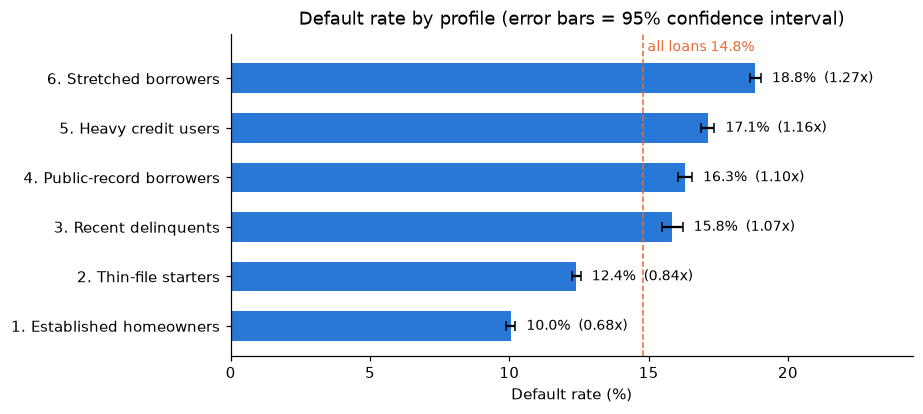

In [23]:
fig, ax = plt.subplots(figsize=(8, 3.8))
labels = [f"{p}. {n}" for p, n in summary["name"].items()]
rate, margin = summary["default_rate"] * 100, summary["margin"] * 100
ax.barh(labels, rate, xerr=margin, color=BLUE, height=0.6, capsize=3)
ax.axvline(base_rate * 100, color=ORANGE, linestyle="--", linewidth=1)
ax.text(
    base_rate * 100,
    FINAL_K - 0.45,
    f" all loans {base_rate:.1%}",
    color=ORANGE,
    fontsize=9,
)
for y, (r, m, lift) in enumerate(zip(rate, margin, summary["lift"])):
    ax.text(r + m + 0.4, y, f"{r:.1f}%  ({lift:.2f}x)", va="center", fontsize=9)
ax.set(
    title="Default rate by profile (error bars = 95% confidence interval)",
    xlabel="Default rate (%)",
    xlim=(0, rate.max() * 1.3),
    ylim=(-0.6, FINAL_K - 0.1),
)
fig.savefig(FIG_DIR / "02_default_rate_by_profile.png", dpi=200, bbox_inches="tight")
plt.show()
# Result: Stretched borrowers default at 18.8% vs 10.0% for Established homeowners, 1.87x the rate.
# The error bars are tiny and none overlap, so these gaps are not random noise.

In [24]:
# Significance test. Chi-square asks: if profile had nothing to do with default, how likely are counts this uneven?
# Cramer's V then measures how strong the link is (0 = none, 1 = profile fully decides default).
counts = pd.crosstab(df["profile"], df["default"])
chi2, p_value, dof, _ = chi2_contingency(counts)
# for a yes/no outcome this is the full Cramer's V formula
cramers_v = np.sqrt(chi2 / len(df))
print(
    f"chi-square = {chi2:,.0f} (dof = {dof}), p-value = {p_value:.1e}, Cramer's V = {cramers_v:.3f}"
)
# Result: p is effectively 0, so default rates definitely differ between profiles. V = 0.09 is small, and
# that's expected: finances alone can't decide who defaults. With 673k loans almost anything is "significant",
# which is why the practical gap (10% vs 18.8%) is the number that matters.

chi-square = 5,665 (dof = 5), p-value = 0.0e+00, Cramer's V = 0.092


### Step 5 · Profiles vs. Lending Club grade, and save

In [25]:
# Are the profiles just grades in disguise? If so, each profile would sit in one or two grades.
# They don't: every profile has borrowers from grade A through E. (Part 4 tests this formally.)
(pd.crosstab(df["profile"], df["grade"], normalize="index") * 100).round(0)

grade,A,B,C,D,E,F,G
profile,,,,,,,
1,33.0,34.0,21.0,8.0,3.0,1.0,0.0
2,26.0,33.0,24.0,11.0,4.0,1.0,0.0
3,13.0,35.0,30.0,15.0,5.0,2.0,0.0
4,11.0,36.0,32.0,15.0,5.0,1.0,0.0
5,23.0,30.0,27.0,14.0,5.0,2.0,0.0
6,14.0,31.0,31.0,16.0,7.0,2.0,0.0


In [26]:
df[["id", "profile", "profile_name"]].to_csv(
    DATA_DIR / "clusters_kmeans.csv", index=False
)
summary.round(4).to_csv(DATA_DIR / "profile_summary.csv")
print(
    f"Saved profiles for {len(df):,} loans -> clusters_kmeans.csv, profile_summary.csv"
)

Saved profiles for 673,314 loans -> clusters_kmeans.csv, profile_summary.csv
